# Machine Learning Lab - 10 Experiments

Open this notebook **from its own folder** (so `datasets/` is found) and use *Run All*.
Each experiment is also available as a stand-alone script `Experiment_XX.py` with the same program logic.
See the project `README.md` for installation, datasets, and which experiments need an external service.

# EX: NO: 1 — FIND-S algorithm
**Aim:** Implement and demonstrate the FIND-S algorithm for finding the most specific
hypothesis based on a given set of training data samples. Read the training data from a `.CSV` file.

**Dataset:** `datasets/enjoysport.csv` (the EnjoySport table printed in the manual).

In [1]:
import csv
from pathlib import Path

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "datasets"

## Load the training data

In [2]:
a = []
with open(DATA_DIR / "enjoysport.csv", "r") as csvfile:
    reader = csv.reader(csvfile)
    next(reader)
    for row in reader:
        a.append(row)

print("The Given Training Data Set")
for row in a:
    print(row)

print("\n The total number of training instances are : ", len(a))

The Given Training Data Set
['sunny', 'warm', 'normal', 'strong', 'warm', 'same', 'yes']
['sunny', 'warm', 'high', 'strong', 'warm', 'same', 'yes']
['rainy', 'cold', 'high', 'strong', 'warm', 'change', 'no']
['sunny', 'warm', 'high', 'strong', 'cool', 'change', 'yes']

 The total number of training instances are :  4


## FIND-S

In [3]:
num_attribute = len(a[0]) - 1

print("\n The initial hypothesis is : ")
hypothesis = ['0'] * num_attribute
print(hypothesis)

for i in range(0, len(a)):
    if a[i][num_attribute] == 'yes':
        for j in range(0, num_attribute):
            if hypothesis[j] == '0' or hypothesis[j] == a[i][j]:
                hypothesis[j] = a[i][j]
            else:
                hypothesis[j] = '?'
    print("\n The hypothesis for the training instance {} is : \n".format(i + 1), hypothesis)

print("\n The Maximally specific hypothesis for the training instance is ")
print(hypothesis)


 The initial hypothesis is : 
['0', '0', '0', '0', '0', '0']

 The hypothesis for the training instance 1 is : 
 ['sunny', 'warm', 'normal', 'strong', 'warm', 'same']

 The hypothesis for the training instance 2 is : 
 ['sunny', 'warm', '?', 'strong', 'warm', 'same']

 The hypothesis for the training instance 3 is : 
 ['sunny', 'warm', '?', 'strong', 'warm', 'same']

 The hypothesis for the training instance 4 is : 
 ['sunny', 'warm', '?', 'strong', '?', '?']

 The Maximally specific hypothesis for the training instance is 
['sunny', 'warm', '?', 'strong', '?', '?']


# EX: NO: 2 — Candidate-Elimination algorithm
**Aim:** For a given set of training data examples stored in a `.CSV` file, implement and
demonstrate the Candidate-Elimination algorithm to output a description of the set of all
hypotheses consistent with the training examples.

**Dataset:** `datasets/enjoysport.csv`

In [4]:
import numpy as np
import pandas as pd
from pathlib import Path

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "datasets"

## Load data

In [5]:
data = pd.DataFrame(data=pd.read_csv(DATA_DIR / "enjoysport.csv"))
concepts = np.array(data.iloc[:, 0:-1])
print(concepts)
target = np.array(data.iloc[:, -1])
print(target)

[['sunny' 'warm' 'normal' 'strong' 'warm' 'same']
 ['sunny' 'warm' 'high' 'strong' 'warm' 'same']
 ['rainy' 'cold' 'high' 'strong' 'warm' 'change']
 ['sunny' 'warm' 'high' 'strong' 'cool' 'change']]
['yes' 'yes' 'no' 'yes']


## Candidate-Elimination

In [6]:
def learn(concepts, target):
    specific_h = concepts[0].copy()
    print("initialization of specific_h and general_h")
    print(specific_h)
    general_h = [["?" for i in range(len(specific_h))] for i in range(len(specific_h))]
    print(general_h)

    for i, h in enumerate(concepts):
        if target[i] == "yes":
            for x in range(len(specific_h)):
                if h[x] != specific_h[x]:
                    specific_h[x] = '?'
                    general_h[x][x] = '?'
                print(specific_h)
        print(specific_h)
        if target[i] == "no":
            for x in range(len(specific_h)):
                if h[x] != specific_h[x]:
                    general_h[x][x] = specific_h[x]
                else:
                    general_h[x][x] = '?'
        print(" steps of Candidate Elimination Algorithm", i + 1)
        print(specific_h)
        print(general_h)

    indices = [i for i, val in enumerate(general_h) if val == ['?', '?', '?', '?', '?', '?']]
    for i in indices:
        general_h.remove(['?', '?', '?', '?', '?', '?'])
    return specific_h, general_h


if __name__ == "__main__":
    s_final, g_final = learn(concepts, target)
    print("Final Specific_h:", s_final, sep="\n")
    print("Final General_h:", g_final, sep="\n")

initialization of specific_h and general_h
['sunny' 'warm' 'normal' 'strong' 'warm' 'same']
[['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?']]
['sunny' 'warm' 'normal' 'strong' 'warm' 'same']
['sunny' 'warm' 'normal' 'strong' 'warm' 'same']
['sunny' 'warm' 'normal' 'strong' 'warm' 'same']
['sunny' 'warm' 'normal' 'strong' 'warm' 'same']
['sunny' 'warm' 'normal' 'strong' 'warm' 'same']
['sunny' 'warm' 'normal' 'strong' 'warm' 'same']
['sunny' 'warm' 'normal' 'strong' 'warm' 'same']
 steps of Candidate Elimination Algorithm 1
['sunny' 'warm' 'normal' 'strong' 'warm' 'same']
[['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?']]
['sunny' 'warm' 'normal' 'strong' 'warm' 'same']
['sunny' 'warm' 'normal' 'strong' 'wa

# EX: NO: 3 — Decision tree using the ID3 algorithm
**Aim:** Write a program to demonstrate the working of the decision tree based ID3 algorithm.
Use an appropriate data set for building the decision tree and apply this knowledge to
classify a new sample.

**Datasets:** `datasets/data3.csv` (training), `datasets/data3_test.csv` (test samples).
*These two files are not printed in the manual; `data3.csv` is the standard 14-row
Play-Tennis table, which reproduces the tree and labels printed in the manual (see README).*

In [7]:
import math
import csv
from pathlib import Path

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "datasets"

## Helper functions

In [8]:
def load_csv(filename):
    lines = csv.reader(open(filename, "r"))
    dataset = list(lines)
    headers = dataset.pop(0)
    return dataset, headers


class Node:
    def __init__(self, attribute):
        self.attribute = attribute
        self.children = []
        self.answer = ""


def subtables(data, col, delete):
    dic = {}
    coldata = [row[col] for row in data]
    attr = sorted(set(coldata))
    counts = [0] * len(attr)
    r = len(data)
    c = len(data[0])
    for x in range(len(attr)):
        for y in range(r):
            if data[y][col] == attr[x]:
                counts[x] += 1
    for x in range(len(attr)):
        dic[attr[x]] = [[0 for i in range(c)] for j in range(counts[x])]
    pos = [0] * len(attr)
    for y in range(r):
        for x in range(len(attr)):
            if data[y][col] == attr[x]:
                if delete:
                    del data[y][col]
                dic[attr[x]][pos[x]] = data[y]
                pos[x] += 1
    return attr, dic


def entropy(S):
    attr = sorted(set(S))
    if len(attr) == 1:
        return 0
    counts = [0, 0]
    for i in range(2):
        counts[i] = sum([1 for x in S if attr[i] == x]) / (len(S) * 1.0)
    sums = 0
    for cnt in counts:
        if cnt != 0:
            sums += -1 * cnt * math.log(cnt, 2)
    return sums


def compute_gain(data, col):
    attr, dic = subtables(data, col, delete=False)
    total_size = len(data)
    entropies = [0] * len(attr)
    ratio = [0] * len(attr)
    total_entropy = entropy([row[-1] for row in data])
    for x in range(len(attr)):
        ratio[x] = len(dic[attr[x]]) / (total_size * 1.0)
        entropies[x] = entropy([row[-1] for row in dic[attr[x]]])
        total_entropy -= ratio[x] * entropies[x]
    return total_entropy


def build_tree(data, features):
    lastcol = [row[-1] for row in data]
    if len(set(lastcol)) == 1:
        node = Node("")
        node.answer = lastcol[0]
        return node

    n = len(data[0]) - 1
    gains = [0] * n
    for col in range(n):
        gains[col] = compute_gain(data, col)
    split = gains.index(max(gains))
    node = Node(features[split])
    fea = features[:split] + features[split + 1:]

    attr, dic = subtables(data, split, delete=True)
    for x in range(len(attr)):
        child = build_tree(dic[attr[x]], fea)
        node.children.append((attr[x], child))
    return node


def print_tree(node, level):
    if node.answer != "":
        print("\t" * level, node.answer)
        return
    print("\t" * level, node.attribute)
    for value, n in node.children:
        print("\t" * (level + 1), value)
        print_tree(n, level + 2)


def classify(node, x_test, features):
    if node.answer != "":
        print(node.answer)
        return
    pos = features.index(node.attribute)
    for value, n in node.children:
        if x_test[pos] == value:
            classify(n, x_test, features)

## Build the tree and classify the test samples

In [9]:
if __name__ == "__main__":
    dataset, features = load_csv(DATA_DIR / "data3.csv")
    node1 = build_tree(dataset, features)

    print("The decision tree for the dataset using ID3 algorithm is")
    print_tree(node1, 0)

    testdata, features = load_csv(DATA_DIR / "data3_test.csv")
    for xtest in testdata:
        print("The test instance:", xtest)
        print("The label for test instance:", end=" ")
        classify(node1, xtest, features)

The decision tree for the dataset using ID3 algorithm is
 Outlook
	 overcast
		 yes
	 rain
		 Wind
			 strong
				 no
			 weak
				 yes
	 sunny
		 Humidity
			 high
				 no
			 normal
				 yes
The test instance: ['rain', 'cool', 'normal', 'strong']
The label for test instance: no
The test instance: ['sunny', 'mild', 'normal', 'strong']
The label for test instance: yes


# EX: NO: 4 — Artificial Neural Network with Back-propagation
**Aim:** Build an Artificial Neural Network by implementing the Back-propagation algorithm
and test the same using appropriate data sets.

No external dataset: the 3-sample (hours slept, hours studied) -> score table from the manual is
defined in the code.

In [10]:
import numpy as np

np.random.seed(42)

## Data and activation function

In [11]:
X = np.array(([2, 9], [1, 5], [3, 6]), dtype=float)
y = np.array(([92], [86], [89]), dtype=float)
X = X / np.amax(X, axis=0)
y = y / 100


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def derivatives_sigmoid(x):
    return x * (1 - x)

## Network configuration and weight initialisation

In [12]:
epoch = 5000
lr = 0.1
inputlayer_neurons = 2
hiddenlayer_neurons = 3
output_neurons = 1

wh = np.random.uniform(size=(inputlayer_neurons, hiddenlayer_neurons))
bh = np.random.uniform(size=(1, hiddenlayer_neurons))
wout = np.random.uniform(size=(hiddenlayer_neurons, output_neurons))
bout = np.random.uniform(size=(1, output_neurons))

## Training (forward propagation + back-propagation)

In [13]:
for i in range(epoch):
    hinp1 = np.dot(X, wh)
    hinp = hinp1 + bh
    hlayer_act = sigmoid(hinp)
    outinp1 = np.dot(hlayer_act, wout)
    outinp = outinp1 + bout
    output = sigmoid(outinp)

    EO = y - output
    outgrad = derivatives_sigmoid(output)
    d_output = EO * outgrad
    EH = d_output.dot(wout.T)
    hiddengrad = derivatives_sigmoid(hlayer_act)
    d_hiddenlayer = EH * hiddengrad

    wout += hlayer_act.T.dot(d_output) * lr
    wh += X.T.dot(d_hiddenlayer) * lr

print("Input: \n" + str(X))
print("Actual Output: \n" + str(y))
print("Predicted Output: \n", output)

Input: 
[[0.66666667 1.        ]
 [0.33333333 0.55555556]
 [1.         0.66666667]]
Actual Output: 
[[0.92]
 [0.86]
 [0.89]]
Predicted Output: 
 [[0.89386475]
 [0.88093792]
 [0.89521896]]


# EX: NO: 5 — Naïve Bayesian classifier (Gaussian, from scratch)
**Aim:** Write a program to implement the naïve Bayesian classifier for a sample training data set
stored as a `.CSV` file. Compute the accuracy of the classifier, considering few test data sets.

**Dataset:** `datasets/naivedata.csv` — Pima Indians Diabetes (768 rows, 8 attributes + class, no header).

In [14]:
import csv
import random
import math
from pathlib import Path

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "datasets"

SEED = 11

## Helper functions

In [15]:
def loadcsv(filename):
    lines = csv.reader(open(filename, "r"))
    dataset = list(lines)
    for i in range(len(dataset)):
        dataset[i] = [float(x) for x in dataset[i]]
    return dataset


def splitdataset(dataset, splitratio):
    trainsize = int(len(dataset) * splitratio)
    trainset = []
    copy = list(dataset)
    while len(trainset) < trainsize:
        index = random.randrange(len(copy))
        trainset.append(copy.pop(index))
    return [trainset, copy]


def separatebyclass(dataset):
    separated = {}
    for i in range(len(dataset)):
        vector = dataset[i]
        if vector[-1] not in separated:
            separated[vector[-1]] = []
        separated[vector[-1]].append(vector)
    return separated


def mean(numbers):
    return sum(numbers) / float(len(numbers))


def stdev(numbers):
    avg = mean(numbers)
    variance = sum([pow(x - avg, 2) for x in numbers]) / float(len(numbers) - 1)
    return math.sqrt(variance)


def summarize(dataset):
    summaries = [(mean(attribute), stdev(attribute)) for attribute in zip(*dataset)]
    del summaries[-1]
    return summaries


def summarizebyclass(dataset):
    separated = separatebyclass(dataset)
    summaries = {}
    for classvalue, instances in separated.items():
        summaries[classvalue] = summarize(instances)
    return summaries


def calculateprobability(x, mean, stdev):
    exponent = math.exp(-(math.pow(x - mean, 2) / (2 * math.pow(stdev, 2))))
    return (1 / (math.sqrt(2 * math.pi) * stdev)) * exponent


def calculateclassprobabilities(summaries, inputvector):
    probabilities = {}
    for classvalue, classsummaries in summaries.items():
        probabilities[classvalue] = 1
        for i in range(len(classsummaries)):
            mean, stdev = classsummaries[i]
            x = inputvector[i]
            probabilities[classvalue] *= calculateprobability(x, mean, stdev)
    return probabilities


def predict(summaries, inputvector):
    probabilities = calculateclassprobabilities(summaries, inputvector)
    bestLabel, bestProb = None, -1
    for classvalue, probability in probabilities.items():
        if bestLabel is None or probability > bestProb:
            bestProb = probability
            bestLabel = classvalue
    return bestLabel


def getpredictions(summaries, testset):
    predictions = []
    for i in range(len(testset)):
        result = predict(summaries, testset[i])
        predictions.append(result)
    return predictions


def getaccuracy(testset, predictions):
    correct = 0
    for i in range(len(testset)):
        if testset[i][-1] == predictions[i]:
            correct += 1
    return (correct / float(len(testset))) * 100.0

## Train, test and report accuracy

In [16]:
def main():
    filename = DATA_DIR / 'naivedata.csv'
    splitratio = 0.67
    random.seed(SEED)
    dataset = loadcsv(filename)
    trainingset, testset = splitdataset(dataset, splitratio)
    print(f'Split {len(dataset)} rows into train={len(trainingset)} and test={len(testset)} rows')
    summaries = summarizebyclass(trainingset)
    predictions = getpredictions(summaries, testset)
    accuracy = getaccuracy(testset, predictions)
    print(f'Accuracy of the classifier is : {accuracy}%')


if __name__ == "__main__":
    main()

Split 768 rows into train=514 and test=254 rows
Accuracy of the classifier is : 71.65354330708661%


# EX: NO: 6 — Naïve Bayes text classifier (accuracy, precision, recall)
**Aim:** Assuming a set of documents that need to be classified, use the naïve Bayesian classifier
model to perform this task. Calculate the accuracy, precision, and recall for your data set.

**Dataset:** `datasets/naivetext.csv` — the 18 labelled sentences printed in the manual
(no header; columns: message, label).

*(The manual says "Built-in Java classes/API" but its program is Python/scikit-learn; this is the Python version.)*

In [17]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn import metrics

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "datasets"

TEST_SIZE = 0.25
RANDOM_STATE = 81

## Load dataset

In [18]:
msg = pd.read_csv(DATA_DIR / 'naivetext.csv', names=['message', 'label'])
print('The dimensions of the dataset', msg.shape)

msg['labelnum'] = msg.label.map({'pos': 1, 'neg': 0})
X = msg.message
y = msg.labelnum
print(X)
print(y)

The dimensions of the dataset (18, 2)
0                      I love this sandwich
1                  This is an amazing place
2        I feel very good about these beers
3                      This is my best work
4                      What an awesome view
5             I do not like this restaurant
6                  I am tired of this stuff
7                    I can't deal with this
8                      He is my sworn enemy
9                       My boss is horrible
10                 This is an awesome place
11    I do not like the taste of this juice
12                          I love to dance
13        I am sick and tired of this place
14                     What a great holiday
15           That is a bad locality to stay
16           We will have good fun tomorrow
17         I went to my enemy's house today
Name: message, dtype: str
0     1
1     1
2     1
3     1
4     1
5     0
6     0
7     0
8     0
9     0
10    1
11    0
12    1
13    0
14    1
15    0
16    1
17    0


## Split, vectorise (Bag-of-Words) and train

In [19]:
xtrain, xtest, ytrain, ytest = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print('\nThe total number of Training Data :', ytrain.shape)
print('The total number of Test Data :', ytest.shape)

count_vect = CountVectorizer()
xtrain_dtm = count_vect.fit_transform(xtrain)
xtest_dtm = count_vect.transform(xtest)
print('\nThe words or Tokens in the text documents\n')
print(count_vect.get_feature_names_out())

df = pd.DataFrame(xtrain_dtm.toarray(), columns=count_vect.get_feature_names_out())
print('\nSample Bag-of-Words representation (first rows):')
print(df.head())

clf = MultinomialNB().fit(xtrain_dtm, ytrain)
predicted = clf.predict(xtest_dtm)


The total number of Training Data : (13,)
The total number of Test Data : (5,)

The words or Tokens in the text documents

['am' 'amazing' 'an' 'and' 'awesome' 'bad' 'best' 'boss' 'dance' 'do'
 'enemy' 'fun' 'good' 'great' 'have' 'he' 'holiday' 'horrible' 'house'
 'is' 'juice' 'like' 'locality' 'love' 'my' 'not' 'of' 'place' 'sick'
 'stay' 'sworn' 'taste' 'that' 'the' 'this' 'tired' 'to' 'today'
 'tomorrow' 'view' 'we' 'went' 'what' 'will' 'work']

Sample Bag-of-Words representation (first rows):
   am  amazing  an  and  awesome  bad  best  boss  dance  do  ...  tired  to  \
0   0        0   1    0        1    0     0     0      0   0  ...      0   0   
1   0        0   0    0        0    1     0     0      0   0  ...      0   1   
2   0        0   0    0        0    0     0     0      1   0  ...      0   1   
3   0        0   0    0        0    0     0     1      0   0  ...      0   0   
4   0        0   1    0        1    0     0     0      0   0  ...      0   0   

   today  tomorr

## Evaluation

In [20]:
print('\nAccuracy of the classifier is', metrics.accuracy_score(ytest, predicted))
print('\nConfusion matrix')
print(metrics.confusion_matrix(ytest, predicted))
print('\nThe value of Precision', metrics.precision_score(ytest, predicted))
print('\nThe value of Recall', metrics.recall_score(ytest, predicted))


Accuracy of the classifier is 0.8

Confusion matrix
[[2 1]
 [0 2]]

The value of Precision 0.6666666666666666

The value of Recall 1.0


# EX: NO: 7 — Bayesian network for heart-disease diagnosis
**Aim:** Write a program to construct a Bayesian network considering medical data. Use this model to
demonstrate the diagnosis of heart patients using the standard Heart Disease Data Set.

**Dataset:** `datasets/heart.csv` — UCI *Cleveland* Heart Disease data (303 rows, 14 columns, `?` = missing,
target `heartdisease` = 0-4).  It is **not** printed in the manual, so it is fetched from the UCI repository
by `download_heart.py` (runs automatically on first use; needs internet once).

**Library note:** newer pgmpy renamed `BayesianModel` to `DiscreteBayesianNetwork` and `MaximumLikelihoodEstimator`
to `DiscreteMLE`; the compatibility block below supports both.

In [21]:
import numpy as np
import pandas as pd
from pathlib import Path

from pgmpy.inference import VariableElimination

try:
    from pgmpy.models import DiscreteBayesianNetwork as BayesianModel
    from pgmpy.parameter_estimator import DiscreteMLE
    MLE_ESTIMATOR = DiscreteMLE()
except ImportError:
    from pgmpy.models import BayesianModel
    from pgmpy.estimators import MaximumLikelihoodEstimator
    MLE_ESTIMATOR = MaximumLikelihoodEstimator

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "datasets"
HEART_CSV = DATA_DIR / "heart.csv"

## Read the Cleveland Heart Disease dataset

In [22]:
def load_heart():
    """Return the Cleveland data frame, or None (after printing instructions) if it cannot be obtained."""
    if not HEART_CSV.exists():
        import sys
        sys.path.insert(0, str(BASE_DIR))
        from download_heart import download_heart_csv
        try:
            download_heart_csv(HEART_CSV)
        except Exception as exc:
            print(f"Could not obtain datasets/heart.csv automatically ({type(exc).__name__}: {exc}).")
            print("Download  processed.cleveland.data  from the UCI repository (URL in download_heart.py),")
            print("or run  python download_heart.py  on a machine with internet, and put heart.csv in datasets/.")
            return None
    return pd.read_csv(HEART_CSV).replace('?', np.nan)


heartDisease = load_heart()

if heartDisease is not None:
    print('Few examples from the dataset are given below')
    print(heartDisease.head())

    print('\n Attributes and datatypes')
    print(heartDisease.dtypes)

Could not obtain datasets/heart.csv automatically (URLError: <urlopen error Tunnel connection failed: 403 Forbidden>).
Download  processed.cleveland.data  from the UCI repository (URL in download_heart.py),
or run  python download_heart.py  on a machine with internet, and put heart.csv in datasets/.


## Create the Bayesian network and learn its CPDs

In [23]:
if heartDisease is not None:
    model = BayesianModel([('age', 'heartdisease'), ('sex', 'heartdisease'),
                           ('exang', 'heartdisease'), ('cp', 'heartdisease'),
                           ('heartdisease', 'restecg'), ('heartdisease', 'chol')])

    print('\nLearning CPD using Maximum likelihood estimators')
    model.fit(heartDisease, estimator=MLE_ESTIMATOR)

## Inference with the Bayesian network

In [24]:
if heartDisease is not None:
    print('\n Inferencing with Bayesian Network:')
    HeartDiseasetest_infer = VariableElimination(model)

    print('\n 1. Probability of HeartDisease given evidence= restecg')
    q1 = HeartDiseasetest_infer.query(variables=['heartdisease'], evidence={'restecg': 1}, show_progress=False)
    print(q1)

    print('\n 2. Probability of HeartDisease given evidence= cp')
    q2 = HeartDiseasetest_infer.query(variables=['heartdisease'], evidence={'cp': 2}, show_progress=False)
    print(q2)

In [25]:
if __name__ == "__main__":
    import sys
    if heartDisease is None and "ipykernel" not in sys.modules:
        sys.exit(2)

# EX: NO: 8 — EM (Gaussian Mixture) vs k-Means clustering
**Aim:** Apply EM algorithm to cluster a set of data stored in a `.CSV` file. Use the same data set for
clustering using k-Means algorithm. Compare the results of these two algorithms and comment on the
quality of clustering.

**Dataset:** `datasets/8-dataset.csv` — UCI Iris (150 rows, no header, class names `Iris-*`).

In [26]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
import sklearn.metrics as metrics

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "datasets"
OUT_DIR = BASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)

## Load data

In [27]:
names = ['Sepal_Length', 'Sepal_Width', 'Petal_Length', 'Petal_Width', 'Class']
dataset = pd.read_csv(DATA_DIR / "8-dataset.csv", names=names)

X = dataset.iloc[:, :-1]
label = {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}
y = [label[c] for c in dataset.iloc[:, -1]]

plt.figure(figsize=(14, 7))
colormap = np.array(['red', 'lime', 'black'])

<Figure size 2800x1400 with 0 Axes>

## Real classes, k-Means and GMM (EM)

The accuracy score of K-Mean:  0.24
The Confusion matrixof K-Mean:
 [[ 0 50  0]
 [48  0  2]
 [14  0 36]]
The accuracy score of EM:  0.3333333333333333
The Confusion matrix of EM:
  [[ 0 50  0]
 [45  0  5]
 [ 0  0 50]]


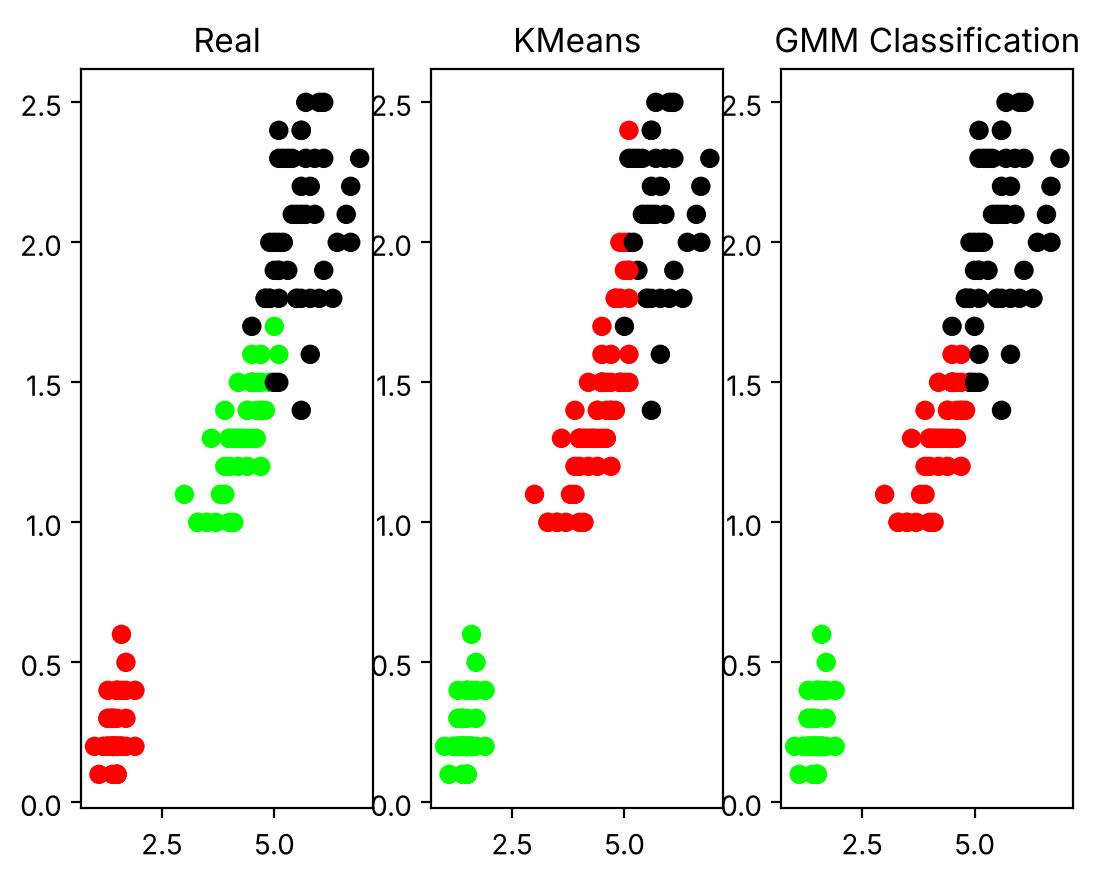

In [28]:
plt.subplot(1, 3, 1)
plt.title('Real')
plt.scatter(X.Petal_Length, X.Petal_Width, c=colormap[y])

model = KMeans(n_clusters=3, random_state=0, n_init=10).fit(X)
plt.subplot(1, 3, 2)
plt.title('KMeans')
plt.scatter(X.Petal_Length, X.Petal_Width, c=colormap[model.labels_])
print('The accuracy score of K-Mean: ', metrics.accuracy_score(y, model.labels_))
print('The Confusion matrixof K-Mean:\n', metrics.confusion_matrix(y, model.labels_))

gmm = GaussianMixture(n_components=3, random_state=0).fit(X)
y_cluster_gmm = gmm.predict(X)
plt.subplot(1, 3, 3)
plt.title('GMM Classification')
plt.scatter(X.Petal_Length, X.Petal_Width, c=colormap[y_cluster_gmm])
print('The accuracy score of EM: ', metrics.accuracy_score(y, y_cluster_gmm))
print('The Confusion matrix of EM:\n ', metrics.confusion_matrix(y, y_cluster_gmm))

plt.savefig(OUT_DIR / "ml_ex08_clusters.png", dpi=120, bbox_inches="tight")
plt.show()

## Comment on cluster quality
Cluster numbers are arbitrary labels, so the raw *accuracy* above is low for both models even though the
groupings are good (e.g. k-Means puts all 50 setosa flowers in one cluster).  A label-permutation-invariant
score gives a fairer comparison:

In [29]:
print('Adjusted Rand Index  -  KMeans:', round(metrics.adjusted_rand_score(y, model.labels_), 4),
      ' GMM(EM):', round(metrics.adjusted_rand_score(y, y_cluster_gmm), 4))

Adjusted Rand Index  -  KMeans: 0.7302  GMM(EM): 0.9039


# EX: NO: 9 — k-Nearest Neighbour on the Iris data set
**Aim:** Write a program to implement k-Nearest Neighbour algorithm to classify the iris data set.
Print both correct and wrong predictions.

**Dataset:** Iris, loaded from scikit-learn (`datasets.load_iris()`), exactly as in the manual.

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn import datasets

RANDOM_STATE = 497

## Load data

In [31]:
iris = datasets.load_iris()

x = iris.data
y = iris.target

print('sepal-length', 'sepal-width', 'petal-length', 'petal-width')
print(x)
print('class: 0-Iris-Setosa, 1- Iris-Versicolour, 2- Iris-Virginica')
print(y)

sepal-length sepal-width petal-length petal-width
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]


## Train and predict

In [32]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=RANDOM_STATE)

classifier = KNeighborsClassifier(n_neighbors=5)
classifier.fit(x_train, y_train)

y_pred = classifier.predict(x_test)

## Evaluation

In [33]:
print('Confusion Matrix')
print(confusion_matrix(y_test, y_pred))
print('Accuracy Metrics')
print(classification_report(y_test, y_pred))

Confusion Matrix
[[20  0  0]
 [ 0 10  0]
 [ 0  1 14]]
Accuracy Metrics
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       0.91      1.00      0.95        10
           2       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.97      0.98      0.97        45
weighted avg       0.98      0.98      0.98        45



## Correct and wrong predictions
*(Added: the aim asks for both to be printed, but the manual's code only prints the matrix and report.)*

In [34]:
names = iris.target_names
correct = [(i, t, p) for i, (t, p) in enumerate(zip(y_test, y_pred)) if t == p]
wrong = [(i, t, p) for i, (t, p) in enumerate(zip(y_test, y_pred)) if t != p]

print(f'\nCorrect predictions: {len(correct)}')
for i, t, p in correct:
    print(f'  sample {i:2d}  features={x_test[i]}  actual={names[t]:<10} predicted={names[p]}')

print(f'\nWrong predictions: {len(wrong)}')
for i, t, p in wrong:
    print(f'  sample {i:2d}  features={x_test[i]}  actual={names[t]:<10} predicted={names[p]}')


Correct predictions: 44
  sample  0  features=[5.6 2.7 4.2 1.3]  actual=versicolor predicted=versicolor
  sample  1  features=[5.7 3.8 1.7 0.3]  actual=setosa     predicted=setosa
  sample  2  features=[5.1 3.5 1.4 0.3]  actual=setosa     predicted=setosa
  sample  3  features=[7.2 3.2 6.  1.8]  actual=virginica  predicted=virginica
  sample  4  features=[6.4 3.2 4.5 1.5]  actual=versicolor predicted=versicolor
  sample  5  features=[6.  3.4 4.5 1.6]  actual=versicolor predicted=versicolor
  sample  6  features=[6.4 3.2 5.3 2.3]  actual=virginica  predicted=virginica
  sample  7  features=[5.  3.  1.6 0.2]  actual=setosa     predicted=setosa
  sample  8  features=[5.6 3.  4.1 1.3]  actual=versicolor predicted=versicolor
  sample  9  features=[5.  3.4 1.6 0.4]  actual=setosa     predicted=setosa
  sample 10  features=[4.7 3.2 1.3 0.2]  actual=setosa     predicted=setosa
  sample 11  features=[4.6 3.1 1.5 0.2]  actual=setosa     predicted=setosa
  sample 12  features=[4.6 3.2 1.4 0.2]  

# EX: NO: 10 — Locally Weighted Regression
**Aim:** Implement the non-parametric Locally Weighted Regression algorithm in order to fit data points.
Select appropriate data set for your experiment and draw graphs.

**Data:** generated in the program (a noisy "W"-shaped curve), as in the manual.  Plots use Bokeh:
in Jupyter they appear inline; as a script they are written to `outputs/ml_ex10_lwr.html` and opened in the browser.

In [35]:
import numpy as np
from pathlib import Path
from bokeh.plotting import figure, show, output_notebook, output_file
from bokeh.layouts import gridplot

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()
OUT_DIR = BASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)

try:
    IN_NOTEBOOK = get_ipython().__class__.__name__ == "ZMQInteractiveShell"
except NameError:
    IN_NOTEBOOK = False
if IN_NOTEBOOK:
    output_notebook()
else:
    output_file(str(OUT_DIR / "ml_ex10_lwr.html"), title="Locally Weighted Regression", mode="inline")

np.random.seed(42)

Loading BokehJS ...

## Locally weighted regression functions

In [36]:
def local_regression(x0, X, Y, tau):
    x0 = np.r_[1, x0]
    X = np.c_[np.ones(len(X)), X]

    xw = X.T * radial_kernel(x0, X, tau)
    beta = np.linalg.pinv(xw @ X) @ xw @ Y

    return x0 @ beta


def radial_kernel(x0, X, tau):
    return np.exp(np.sum((X - x0) ** 2, axis=1) / (-2 * tau * tau))

## Generate the data set

In [37]:
n = 1000
X = np.linspace(-3, 3, num=n)
print("The Data Set ( 10 Samples) X :\n", X[1:10])
Y = np.log(np.abs(X ** 2 - 1) + .5)
print("The Fitting Curve Data Set (10 Samples) Y :\n", Y[1:10])

X += np.random.normal(scale=.1, size=n)
print("Normalised (10 Samples) X :\n", X[1:10])

domain = np.linspace(-3, 3, num=300)
print(" Xo Domain Space(10 Samples) :\n", domain[1:10])

The Data Set ( 10 Samples) X :
 [-2.99399399 -2.98798799 -2.98198198 -2.97597598 -2.96996997 -2.96396396
 -2.95795796 -2.95195195 -2.94594595]
The Fitting Curve Data Set (10 Samples) Y :
 [2.13582188 2.13156806 2.12730467 2.12303166 2.11874898 2.11445659
 2.11015444 2.10584249 2.10152068]
Normalised (10 Samples) X :
 [-3.00782042 -2.92321913 -2.829679   -2.99939131 -2.99338367 -2.80604268
 -2.88121449 -2.99889939 -2.89168994]
 Xo Domain Space(10 Samples) :
 [-2.97993311 -2.95986622 -2.93979933 -2.91973244 -2.89966555 -2.87959866
 -2.85953177 -2.83946488 -2.81939799]


## Fit for different bandwidths (tau) and plot

In [38]:
def plot_lwr(tau):
    prediction = [local_regression(x0, X, Y, tau) for x0 in domain]
    plot = figure(width=400, height=400)
    plot.title.text = 'tau=%g' % tau
    plot.scatter(X, Y, alpha=.3)
    plot.line(domain, prediction, line_width=2, color='red')
    return plot, prediction


if __name__ == "__main__":
    taus = [10., 1., 0.1, 0.01]
    plots_and_preds = [plot_lwr(t) for t in taus]
    show(gridplot([[plots_and_preds[0][0], plots_and_preds[1][0]],
                   [plots_and_preds[2][0], plots_and_preds[3][0]]]))
    for t, (_, pred) in zip(taus, plots_and_preds):
        print(f"tau={t:<5g} fitted curve: min={min(pred):.3f} max={max(pred):.3f}")

tau=10    fitted curve: min=0.765 max=0.824
tau=1     fitted curve: min=0.243 max=2.196
tau=0.1   fitted curve: min=-0.367 max=2.089
tau=0.01  fitted curve: min=-0.536 max=2.115
